# ML & NN, HW1 – Shira Tankus

In [ ]:
# Automatically install required packages if missing in the environment
%pip install numpy pandas matplotlib scipy seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 54.5 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 61.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 60.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 67.0 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 68.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 46.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 64.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [seaborn]0/11 [seaborn]ib]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import scipy.io as sio
import seaborn as sns

sns.set_theme(style="whitegrid")
%matplotlib inline

In [4]:
import zipfile

with zipfile.ZipFile("v1-v2_gratings.zip", "r") as zip_ref:
    zip_ref.extract("v1-v2_gratings/mat_neural_data/105l001p16.mat", path=".")

data = sio.loadmat("v1-v2_gratings/mat_neural_data/105l001p16.mat")
print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'neuralData'])


# **Part 1: From raw spikes to a tuning curve**

## 1. Number of Neurons

In [5]:
# Unpack raw arrays
trials_data = data['neuralData'][0, 0][0]  # shape (6400, 2)
stim_orientations = data['neuralData'][0, 0][1].flatten()  # shape (6400,)
num_trials = len(trials_data) # 6400 trials
num_v1_neurons = trials_data[0][0].shape[0]  # 159 neurons
time_points = trials_data[0][0].shape[1]    # 1280 ms
print(f"Total V1 Neurons: {num_v1_neurons}")

Total V1 Neurons: 159


### Count of spikes

In [6]:
v1_spike_counts = np.zeros((num_trials, num_v1_neurons)) # (6400 trials, 159 neurons)

# Extract the trial data and sum spikes
for i in range(num_trials):
    trial_data = trials_data[i][0].toarray()
    v1_spike_counts[i] = trial_data[:, :1280].sum(axis=1)

print(v1_spike_counts[0])

[ 28.  11.  13.  16.  28.  52.   1.  11.  27.  15.   9.  18.  59.   9.
   3.  23.  17.  17.   8.  21.  38.  16.   3.   0.  11.  25.   1.  33.
   8.  43.  34.   9.   0.   1.   6.  19.  11.  11.  30. 113.   7.  38.
  12.  41.  43.  32.   4.  20.  26.  35.  35.  20.  10.   6.  14.  30.
   4.  48.   2.   4.  13.   6.  10.  10.   0.  28.  20.  12.  54.  43.
  24.   8.   2.   7.   3.  74.  39.   9.  29.  30.  11.  17.  41.  11.
  18.   7.  22.   4.   3.  18.  10.  29.  24.  64.  38. 101.  36.   0.
  23.  26.  12.   8.  47.  50.   6.   6.  37.  30.   7.  11.   8.   2.
   3.   6.  29.  18.   1.  35.  11.   4.  27.  85.  22.   1.  35.  13.
  15.  34.  20.   5.   0.  53.  26.   1.  28.   1.  19.   8.   4.   1.
   3.  30.  27.  13.  10.  22.   3.  66.   3.  61.   0.  10.  75.  22.
   2.  25.   8.  37.  25.]


## 2+3. Trials per orientation and orientation labels

In [7]:
trial_per_orientation = np.unique(stim_orientations, return_counts=True)
print(trial_per_orientation) # first value in each array refers to the baseline condition

(array([0, 1, 2, 3, 4, 5, 6, 7, 8], dtype=uint8), array([3200,  400,  400,  400,  400,  400,  400,  400,  400]))


In [8]:
gratings = np.arange(1, 9)
mean_tuning_curves = np.zeros((8, num_v1_neurons))

for i, ori in enumerate(gratings):
    trial_indices = np.where(stim_orientations == ori)[0] # trials of specific orientation
    
    # spike count for the trials and mean
    mean_tuning_curves[i, :] = v1_spike_counts[trial_indices, :].mean(axis=0)

print(f"Mean Tuning Curves Shape: {mean_tuning_curves.shape}")

Mean Tuning Curves Shape: (8, 159)


## 4+5. Mean orientation tuning curve and selected Neuron

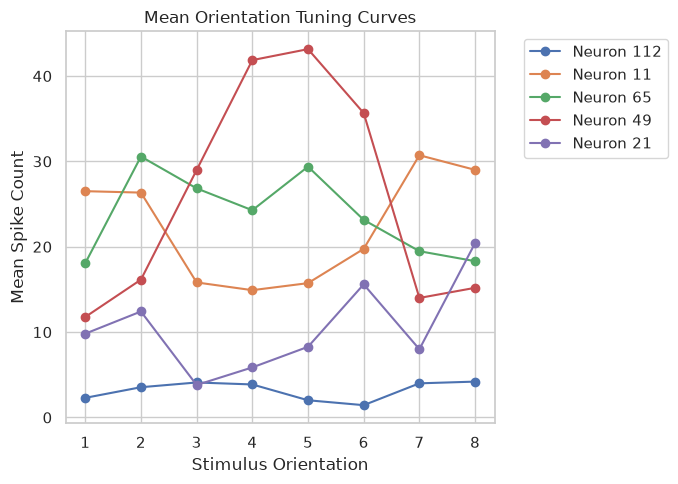

In [9]:
plt.figure(figsize=(7, 5))
neurons_to_plot = [112, 11, 65, 49, 21] # Neuron 49 selected

for n in neurons_to_plot:
    plt.plot(gratings, mean_tuning_curves[:, n], marker='o', label=f'Neuron {n}')

plt.title('Mean Orientation Tuning Curves')
plt.xlabel('Stimulus Orientation')
plt.ylabel('Mean Spike Count')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# **Part 2: Polynomial regression**

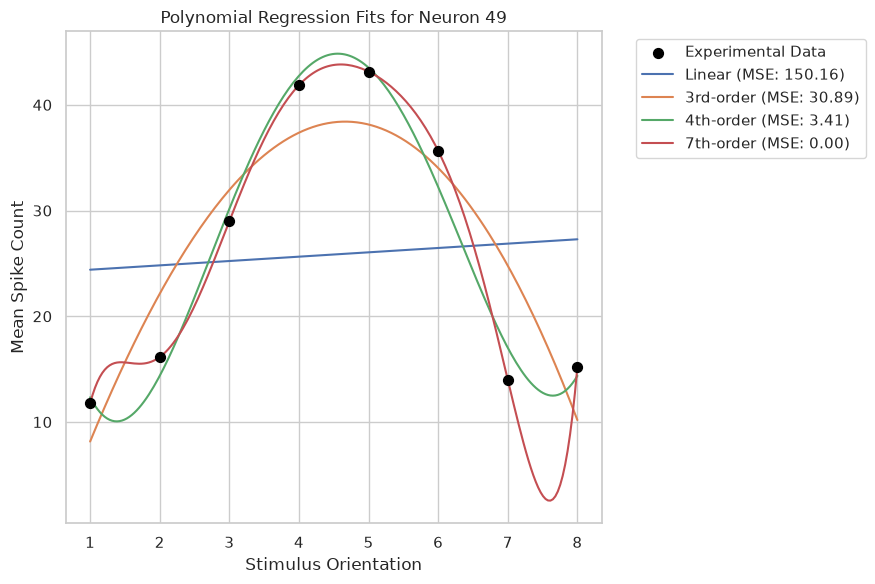

Mean Squared Error (MSE):
Linear: 150.159
3rd-order: 30.892
4th-order: 3.415
7th-order: 0.000


In [10]:
x = gratings  # orientations 1-8
y = mean_tuning_curves[:, 49]  # Neuron 49 mean responses
x_dense = np.linspace(1, 8, 200)
poly_degrees = {'Linear': 1, '3rd-order': 3, '4th-order': 4, '7th-order': 7}

plt.figure(figsize=(9, 6))
plt.scatter(x, y, color='black', s=50, zorder=5, label='Experimental Data')

# Fit, plot and calculate MSE
mse_results = {}

for name, deg in poly_degrees.items():
    coeffs = np.polyfit(x, y, deg)
    y_pred = np.polyval(coeffs, x)
    mse = np.mean((y - y_pred) ** 2)
    mse_results[name] = mse
    y_dense = np.polyval(coeffs, x_dense)
    plt.plot(x_dense, y_dense, label=f'{name} (MSE: {mse:.2f})')

plt.title('Polynomial Regression Fits for Neuron 49')
plt.xlabel('Stimulus Orientation')
plt.ylabel('Mean Spike Count')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# MSE Summary
print("Mean Squared Error (MSE):")
for name, mse in mse_results.items():
    print(f"{name}: {mse:.3f}")

# **Part 3: Nonlinear regression**

In [11]:
def gaussian(x, B, A, mu, sigma):
    return B + A*np.exp(-(x-mu)**2/(2*sigma**2))

# Gaussian parameters and MSE
initial_guess = [10, 35, 4.5, 1.0] 
popt, pcov = curve_fit(gaussian, x, y, p0=initial_guess)
B_fit, A_fit, mu_fit, sigma_fit = popt
y_gauss = gaussian(x, B_fit, A_fit, mu_fit, sigma_fit)
mse_gauss = np.mean((y - y_gauss) ** 2)

print("Fitted Parameters:")
print(f"Baseline (B) = {B_fit:.2f}")
print(f"Amplitude (A) = {A_fit:.2f}")
print(f"Preferred Orientation (mu) = {mu_fit:.2f}")
print(f"Tuning Width (sigma) = {sigma_fit:.2f}\n")
print(f"Gaussian MSE: {mse_gauss:.3f}")

Fitted Parameters:
Baseline (B) = 11.01
Amplitude (A) = 34.74
Preferred Orientation (mu) = 4.63
Tuning Width (sigma) = 1.37

Gaussian MSE: 5.612


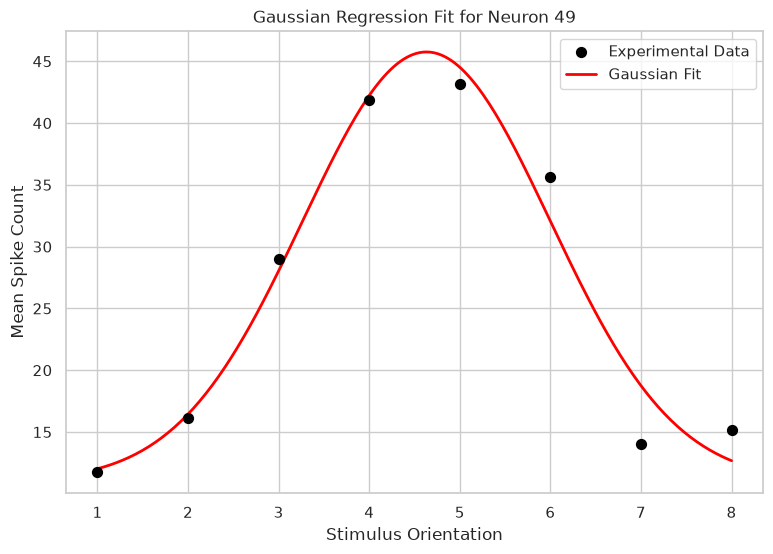

In [12]:
# Plot the gaussian fit for Neuron 49
plt.figure(figsize=(9, 6))
plt.scatter(x, y, color='black', s=50, zorder=5, label='Experimental Data')

y_dense_gauss = gaussian(x_dense, B_fit, A_fit, mu_fit, sigma_fit)
plt.plot(x_dense, y_dense_gauss, color='red', linewidth=2, label=f'Gaussian Fit')

plt.title('Gaussian Regression Fit for Neuron 49')
plt.xlabel('Stimulus Orientation')
plt.ylabel('Mean Spike Count')
plt.legend()
plt.show()

# **Part 4: A problem with orientation**

In [13]:
def vonMises(x, B, A, mu, k):
    # Units conversion: 22.5(deg)*pi/180(deg) = pi/8
    theta_rad = (x - 1) * (np.pi / 8) # -1 for index conversion (start from 0)
    mu_rad = (mu - 1) * (np.pi / 8)
    return B + A * np.exp(k * (np.cos(2 * (theta_rad - mu_rad))))

initial_guess = [11.0, 30.0, 4.63, 1.5]
parameter_bounds = ([0, 20, 1, 0.1], [30, 60, 8, 10.0])

popt, pcov = curve_fit(vonMises, x, y, p0=initial_guess, bounds=parameter_bounds)
B_fit, A_fit, mu_fit, k_fit = popt

# von Mises parameters and MSE
y_vonMises = vonMises(x, B_fit, A_fit, mu_fit, k_fit)
mse_vonMises = np.mean((y - y_vonMises) ** 2)

print("Fitted Parameters:")
print(f"Baseline (B) = {B_fit:.2f}")
print(f"Amplitude (A) = {A_fit:.2f}")
print(f"Preferred Orientation (mu) = {mu_fit:.2f}")
print(f"Concentration (kappa) = {k_fit:.2f}\n")
print(f"von Mises MSE: {mse_vonMises:.3f}")

Fitted Parameters:
Baseline (B) = 0.00
Amplitude (A) = 23.06
Preferred Orientation (mu) = 4.63
Concentration (kappa) = 0.69

von Mises MSE: 5.996


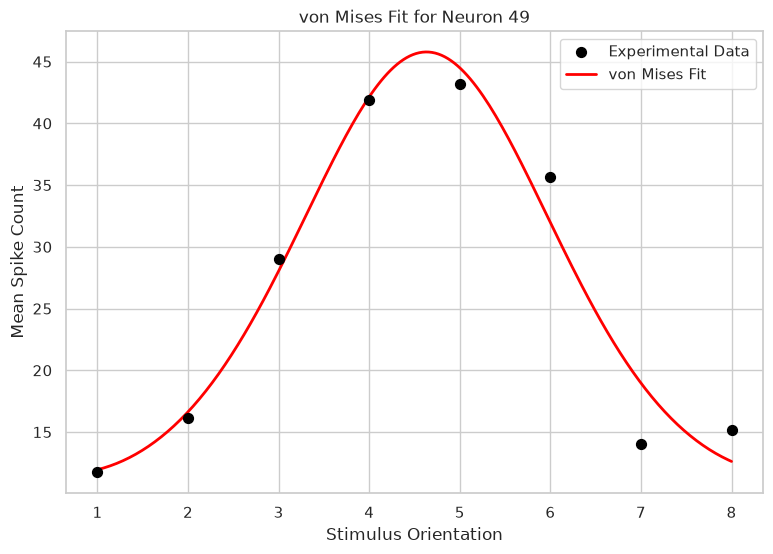

In [14]:
# Plot the von Mises fit for Neuron 49
plt.figure(figsize=(9, 6))
plt.scatter(x, y, color='black', s=50, zorder=5, label='Experimental Data') 

y_dense_vonMises = vonMises(x_dense, B_fit, A_fit, mu_fit, k_fit)
plt.plot(x_dense, y_dense_vonMises, color='red', linewidth=2, label=f'von Mises Fit') 

plt.title('von Mises Fit for Neuron 49')
plt.xlabel('Stimulus Orientation')
plt.ylabel('Mean Spike Count')
plt.legend()
plt.show()

# **Part 5: Comparing the models and evaluating generalization**

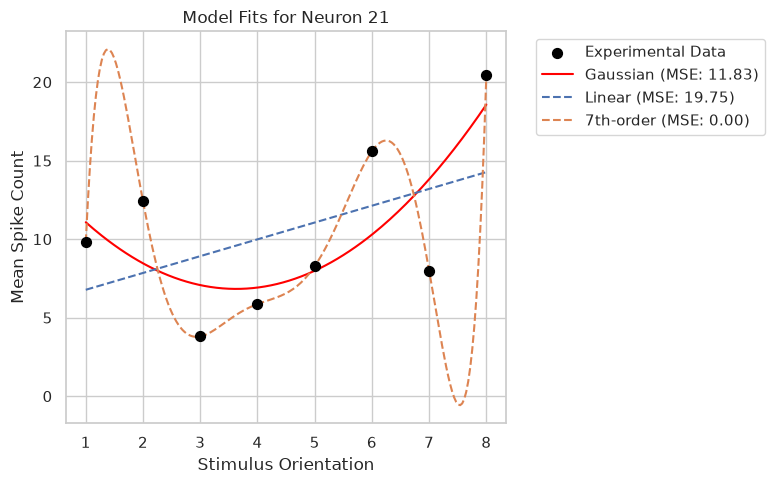

Neuron 21:
Gaussian MSE: 11.825
Linear MSE: 19.747
7th-order MSE: 0.000



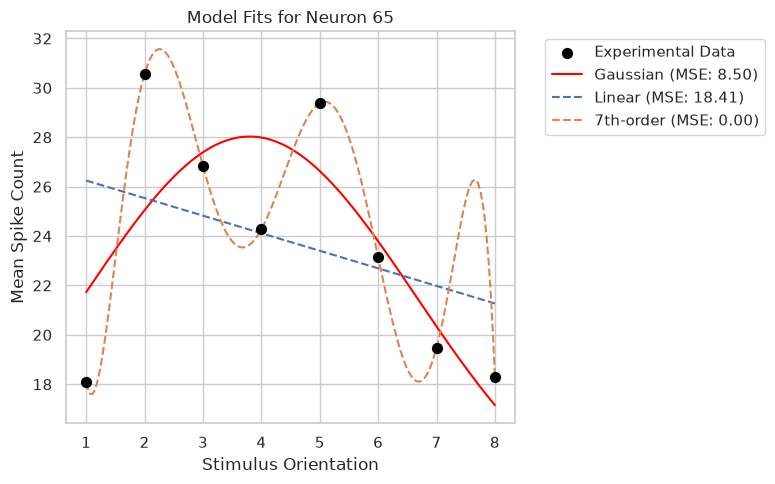

Neuron 65:
Gaussian MSE: 8.499
Linear MSE: 18.406
7th-order MSE: 0.000



In [15]:
# Fit andd plot models for noisy neurons 21 and 65
noisy_neurons = [21, 65]
x_dense = np.linspace(1, 8, 200)

for n in noisy_neurons:
  y_noisy = mean_tuning_curves[:, n]

  plt.figure(figsize=(8, 5))
  plt.scatter(x, y_noisy, color='black', s=50, zorder=5, label='Experimental Data')
 
  # Gaussian
  popt, _ = curve_fit(gaussian, x, y_noisy, p0=[y_noisy.mean(), np.ptp(y_noisy), 4.5, 1.0])
  y_gauss_dense = gaussian(x_dense, *popt)
  mse_g = np.mean((y_noisy - gaussian(x, *popt)) ** 2)
  plt.plot(x_dense, y_gauss_dense, color='red', label=f'Gaussian (MSE: {mse_g:.2f})')
    
  # Linear
  coeffs_lin = np.polyfit(x, y_noisy, 1)
  mse_l = np.mean((y_noisy - np.polyval(coeffs_lin, x)) ** 2)
  plt.plot(x_dense, np.polyval(coeffs_lin, x_dense), linestyle='--', label=f'Linear (MSE: {mse_l:.2f})')
  
  # 7th-order polynomial
  coeffs_7th = np.polyfit(x, y_noisy, 7)
  mse_7 = np.mean((y_noisy - np.polyval(coeffs_7th, x)) ** 2)
  plt.plot(x_dense, np.polyval(coeffs_7th, x_dense), linestyle='--', label=f'7th-order (MSE: {mse_7:.2f})')
  
  plt.title(f'Model Fits for Neuron {n}')
  plt.xlabel('Stimulus Orientation')
  plt.ylabel('Mean Spike Count')
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
  plt.tight_layout()
  plt.show()

  print(f'Neuron {n}:')
  print(f'Gaussian MSE: {mse_g:.3f}')
  print(f'Linear MSE: {mse_l:.3f}')
  print(f'7th-order MSE: {mse_7:.3f}\n')